# Attack Direction Model — MLB Statcast
Predicts `attack_direction_degrees` (horizontal bat path angle at contact).  
Positive = pull-side, Negative = opposite-field.

**Workflow**
1. Pull Statcast data (2024 season — first year with swing tracking)
2. Explore target distribution
3. Engineer features
4. Train XGBoost
5. Evaluate & inspect feature importance
6. Save artifacts for FL inference


In [1]:
# ── Imports ───────────────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import joblib
from pathlib import Path

from pybaseball import statcast
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

print("Imports OK")


Imports OK


## 1. Pull Statcast Data
2024 is the first season MLB tracked swing mechanics (`bat_speed`, `swing_length`, `attack_direction_degrees`).  
Pulling the full season takes a few minutes — results are cached to `statcast_2024.parquet` so you only pull once.


In [2]:
# ── Pull / load from cache ────────────────────────────────────────────────────
CACHE_PATH = Path("statcast_2024.parquet")

if CACHE_PATH.exists():
    print("Loading from cache …")
    raw = pd.read_parquet(CACHE_PATH)
else:
    print("Pulling from Baseball Savant (this takes ~5 minutes) …")
    # Split into monthly chunks to avoid timeouts
    chunks = []
    date_ranges = [
        ("2024-03-20", "2024-04-30"),
        ("2024-05-01", "2024-05-31"),
        ("2024-06-01", "2024-06-30"),
        ("2024-07-01", "2024-07-31"),
        ("2024-08-01", "2024-08-31"),
        ("2024-09-01", "2024-09-29"),
    ]
    for start, end in date_ranges:
        print(f"  {start} → {end}")
        chunk = statcast(start, end, verbose=False)
        chunks.append(chunk)
    raw = pd.concat(chunks, ignore_index=True)
    raw.to_parquet(CACHE_PATH)
    print(f"Cached to {CACHE_PATH}")

print(f"Shape: {raw.shape}")
print(f"Columns with 'attack': {[c for c in raw.columns if 'attack' in c.lower()]}")
print(f"Columns with 'bat_speed': {[c for c in raw.columns if 'bat_speed' in c.lower()]}")


Pulling from Baseball Savant (this takes ~5 minutes) …
  2024-03-20 → 2024-04-30


100%|██████████| 42/42 [01:24<00:00,  2.01s/it]


  2024-05-01 → 2024-05-31


100%|██████████| 31/31 [00:54<00:00,  1.76s/it]


  2024-06-01 → 2024-06-30


...

  2024-08-01 → 2024-08-31


100%|██████████| 31/31 [00:49<00:00,  1.60s/it]


  2024-09-01 → 2024-09-29


100%|██████████| 29/29 [00:47<00:00,  1.64s/it]


Cached to statcast_2024.parquet
Shape: (731904, 118)
Columns with 'attack': ['attack_angle', 'attack_direction']
Columns with 'bat_speed': ['bat_speed']


## 2. Explore the Target Variable

In [4]:
raw.columns

Index(['pitch_type', 'game_date', 'release_speed', 'release_pos_x',
       'release_pos_z', 'player_name', 'batter', 'pitcher', 'events',
       'description',
       ...
       'batter_days_until_next_game', 'api_break_z_with_gravity',
       'api_break_x_arm', 'api_break_x_batter_in', 'arm_angle', 'attack_angle',
       'attack_direction', 'swing_path_tilt',
       'intercept_ball_minus_batter_pos_x_inches',
       'intercept_ball_minus_batter_pos_y_inches'],
      dtype='object', length=118)

In [306]:
# ── Target availability ───────────────────────────────────────────────────────
TARGET = "attack_direction"

total    = len(raw)
has_ad   = raw[TARGET].notna().sum()
has_bs   = raw["bat_speed"].notna().sum()
print(f"Total pitches        : {total:,}")
print(f"Has attack_direction : {has_ad:,}  ({has_ad/total*100:.1f}%)")
print(f"Has bat_speed        : {has_bs:,}  ({has_bs/total*100:.1f}%)")

# Filter to swings with full tracking data
CONTACT_EVENTS = {
    "hit_into_play", "field_error", "single", "double", "triple",
    "home_run", "field_out", "force_out", "grounded_into_double_play",
    "double_play", "triple_play", "sac_fly", "sac_bunt", "fielders_choice",
    "fielders_choice_out", "sac_fly_double_play",
}

swing_mask = (
    raw[TARGET].notna() &
    raw["bat_speed"].notna() &
    raw["swing_length"].notna() &
    raw["launch_speed"].notna() &
    raw["hc_x"].notna() &
    raw["stand"].notna() &
    raw["pitch_type"].notna() &
    raw["events"].isin(CONTACT_EVENTS)          # ← contact only
)
df_swings = raw[swing_mask].copy()
print(f"\nSwings with full tracking: {len(df_swings):,}")
print(f"\n{TARGET} distribution:")
print(df_swings[TARGET].describe().round(2))


Total pitches        : 731,904
Has attack_direction : 316,387  (43.2%)
Has bat_speed        : 316,387  (43.2%)

Swings with full tracking: 113,337

attack_direction distribution:
count   113337.000
mean         0.230
std         14.320
min       -179.650
25%         -7.990
50%          0.180
75%          8.650
max        179.680
Name: attack_direction, dtype: Float64


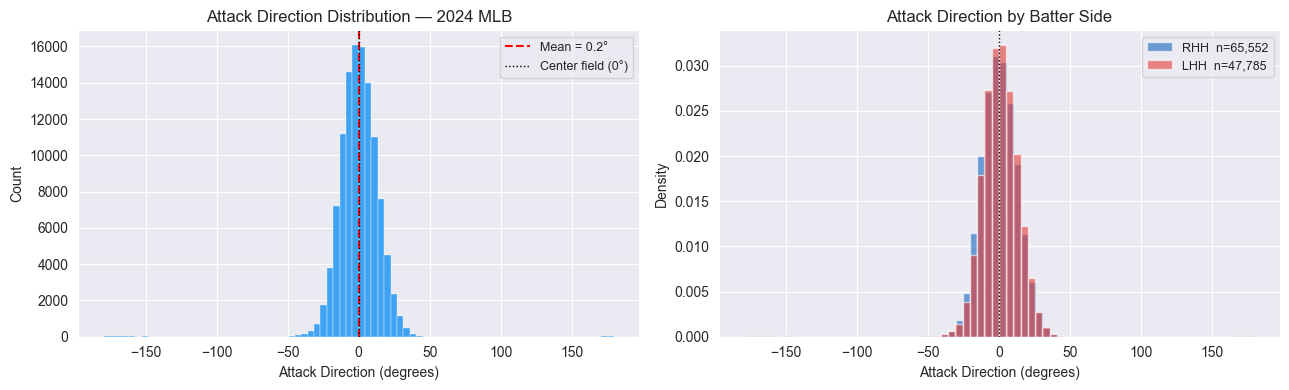

In [307]:
# ── Distribution plot ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ad = df_swings[TARGET]

# Left: overall histogram
axes[0].hist(ad, bins=80, color="#2196F3", alpha=0.85, edgecolor="white", linewidth=0.3)
axes[0].axvline(ad.mean(), color="red", linewidth=1.5, linestyle="--", label=f"Mean = {ad.mean():.1f}°")
axes[0].axvline(0, color="black", linewidth=1, linestyle=":", label="Center field (0°)")
axes[0].set_xlabel("Attack Direction (degrees)")
axes[0].set_ylabel("Count")
axes[0].set_title("Attack Direction Distribution — 2024 MLB")
axes[0].legend(fontsize=9)

# Right: split by batter side
for side, color, label in [("R", "#1565C0", "RHH"), ("L", "#E53935", "LHH")]:
    sub = df_swings[df_swings["stand"] == side][TARGET]
    axes[1].hist(sub, bins=70, alpha=0.6, color=color, label=f"{label}  n={len(sub):,}", density=True)
axes[1].axvline(0, color="black", linewidth=1, linestyle=":")
axes[1].set_xlabel("Attack Direction (degrees)")
axes[1].set_ylabel("Density")
axes[1].set_title("Attack Direction by Batter Side")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


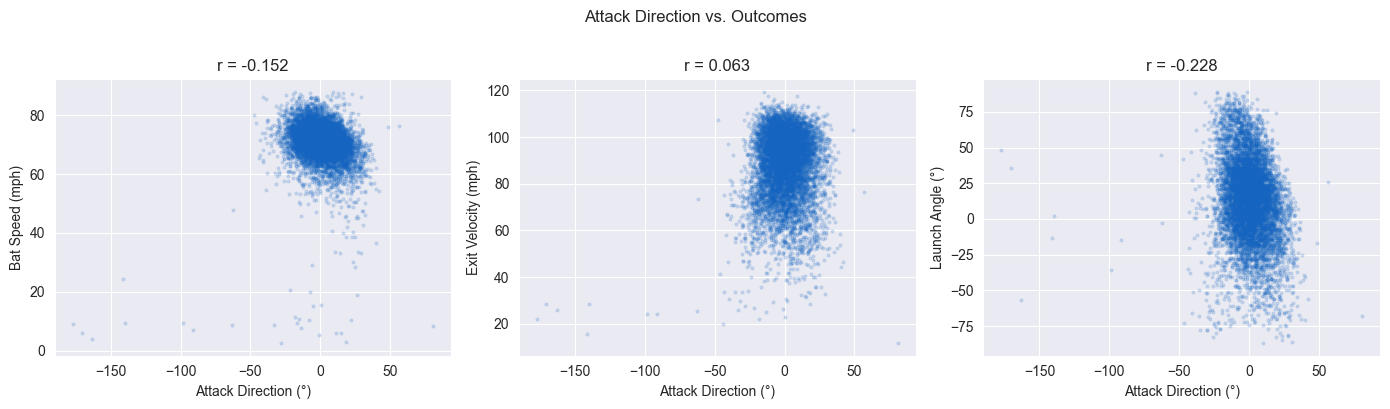

In [308]:
# ── Attack direction vs. key outcomes ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

pairs = [
    ("bat_speed",     "Bat Speed (mph)"),
    ("launch_speed",  "Exit Velocity (mph)"),
    ("launch_angle",  "Launch Angle (°)"),
]
for ax, (col, label) in zip(axes, pairs):
    sample = df_swings.sample(min(8000, len(df_swings)), random_state=42)
    ax.scatter(sample[TARGET], sample[col], alpha=0.15, s=4, color="#1565C0")
    r = sample[[TARGET, col]].corr().iloc[0, 1]
    ax.set_xlabel("Attack Direction (°)")
    ax.set_ylabel(label)
    ax.set_title(f"r = {r:.3f}")

plt.suptitle("Attack Direction vs. Outcomes", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()


## 3. Feature Engineering
Edit this cell to add, remove, or transform features before training.

**Current feature groups:**
- `SWING_FEATURES` — bat speed, swing length  
- `PITCH_FEATURES` — location, movement, velocity  
- `COUNT_FEATURES` — balls, strikes, situational flags  
- `OUTCOME_FEATURES` — exit velo, launch angle, normalized spray direction  
- `CAT_FEATURES` — pitch type, handedness, matchup (all integer-encoded)


In [482]:
# ── Pitch type encoding ───────────────────────────────────────────────────────
# Edit this map to group pitch types differently
PITCH_TYPE_MAP = {
    "FF": 0, "FA": 0,            # 4-seam
    "SI": 1, "FT": 1,            # sinker / 2-seam
    "FC": 2,                      # cutter
    "SL": 3, "ST": 3, "SV": 3,   # slider / sweeper
    "CH": 4, "FS": 4, "FO": 4,   # changeup / splitter
    "CU": 5, "KC": 5, "CS": 5,   # curveball
    "KN": 6,                      # knuckleball
    "EP": 7,                      # eephus
}
STAND_MAP    = {"R": 0, "L": 1}
P_THROWS_MAP = {"R": 0, "L": 1}

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # ── Location relative to batter (pull-side always positive)
    df["plate_x_rel"] = np.where(df["stand"] == "R", df["plate_x"], -df["plate_x"])

    # ── Vertical location relative to strike zone midpoint
    df["sz_mid"]      = (df["sz_top"] + df["sz_bot"]) / 2
    df["plate_z_rel"] = df["plate_z"] - df["sz_mid"]

    # ── Count flags
    df["is_2_strikes"]    = (df["strikes"] == 2).astype(int)
    df["is_hitter_count"] = (
        ((df["balls"] == 2) & (df["strikes"] == 0)) |
        ((df["balls"] == 3) & (df["strikes"] <= 1))
    ).astype(int)

    # ── Categorical encodings
    df["pitch_type_enc"] = df["pitch_type"].map(PITCH_TYPE_MAP).fillna(9).astype(int)
    df["stand_enc"]      = df["stand"].map(STAND_MAP).fillna(0).astype(int)
    df["p_throws_enc"]   = df["p_throws"].map(P_THROWS_MAP).fillna(0).astype(int)
    df["matchup_enc"]    = df["stand_enc"] * 2 + df["p_throws_enc"]

    # ── Normalise spray direction: pull = positive for both sides
    df["hc_x_norm"] = np.where(df["stand"] == "R",
                                df["hc_x"] - 125,
                                125 - df["hc_x"])

    # ── Contact depth
    if "intercept_ball_minus_batter_pos_y_inches" in df.columns:
        pcts = df["intercept_ball_minus_batter_pos_y_inches"].quantile([0.9])
        print(pcts.round(2))
        depth_bins   = [-np.inf] + pcts.tolist() + [np.inf]
        depth_labels = [0, 1]
        df["contact_depth_bin"] = pd.cut(
            depth_raw, bins=depth_bins, labels=depth_labels, right=True
        ).astype(float).fillna(2)
    else:
        print("⚠  intercept_ball_minus_batter_pos_y_inches not found — depth features set to 0")
        df["contact_depth_bin"] = 2.0

    return df

df = engineer_features(df_swings)
print(f"Engineered dataframe: {df.shape}")
print(df[["plate_x_rel", "plate_z_rel", "hc_x_norm", "is_2_strikes", "pitch_type_enc"]].head(3))


0.900   39.940
Name: intercept_ball_minus_batter_pos_y_inches, dtype: Float64
Engineered dataframe: (113337, 129)
   plate_x_rel  plate_z_rel  hc_x_norm  is_2_strikes  pitch_type_enc
0       -0.898       -0.188   -119.420             0               4
3       -0.168        0.370     23.970             0               3
6       -0.928       -0.336    -49.530             1               1


In [483]:
# ── Contact depth features ────────────────────────────────────────────────────
# intercept_ball_minus_batter_y_inches:
#   negative = out front, positive = deep/jammed

if "intercept_ball_minus_batter_pos_y_inches" in df.columns:
    depth_raw = df["intercept_ball_minus_batter_pos_y_inches"]

    # Bin into 5 ordered buckets to reduce per-swing noise
    # Adjust boundaries after checking your raw distribution
    pcts = df["intercept_ball_minus_batter_pos_y_inches"].quantile([0.9])
    print(pcts.round(2))
    depth_bins   = [-np.inf] + pcts.tolist() + [np.inf]
    depth_labels = [0, 1]
    df["contact_depth_bin"] = pd.cut(
        depth_raw, bins=depth_bins, labels=depth_labels, right=True
    ).astype(float).fillna(2)

    # Interaction: depth × spray (pull = positive for both sides)
    df["depth_x_spray"]    = df["contact_depth_bin"] * df["hc_x_norm"]
    # Interaction: depth × pitch location
    # Z-score plate_x_rel within batter side before forming the interaction
    for side in ["R", "L"]:
        mask = df["stand"] == side
        mu   = df.loc[mask, "plate_x_rel"].mean()
        sig  = df.loc[mask, "plate_x_rel"].std()
        df.loc[mask, "plate_x_rel_std"] = (df.loc[mask, "plate_x_rel"] - mu) / sig

    df["depth_x_location"] = df["contact_depth_bin"] * df["plate_x_rel_std"]

else:
    print("⚠  intercept_ball_minus_batter_pos_y_inches not found — depth features set to 0")
    df["contact_depth_bin"]  = 2.0
    df["depth_x_spray"]      = 0.0
    df["depth_x_location"]   = 0.0

0.900   39.940
Name: intercept_ball_minus_batter_pos_y_inches, dtype: Float64


In [484]:
# ── Approach angles from kinematics ──────────────────────────────────────────
# Statcast reference point: (vx0, vy0, vz0) and (ax, ay, az) are measured
# at y0 = 50 feet from home plate. We integrate to y = 17/12 ft (front of plate).

Y0          = 50.0       # feet, reference point
Y_PLATE     = 17 / 12    # feet, front of plate

def compute_approach_angles(df):
    # Time to travel from y0 to plate
    # y(t) = y0 + vy0*t + 0.5*ay*t^2 = Y_PLATE  →  solve quadratic
    a = 0.5 * df["ay"]
    b = df["vy0"]
    c = Y0 - Y_PLATE

    discriminant = b**2 - 4*a*c
    # Take the smaller positive root (first time ball reaches plate)
    t_plate = (-b - np.sqrt(discriminant.clip(lower=0))) / (2 * a)

    # Velocity components at plate
    vx_plate = df["vx0"] + df["ax"] * t_plate
    vy_plate = df["vy0"] + df["ay"] * t_plate
    vz_plate = df["vz0"] + df["az"] * t_plate

    # Approach angles (degrees)
    df["vaa"] = np.degrees(np.arctan(vz_plate / vy_plate.abs()))
    df["haa"] = np.degrees(np.arctan(vx_plate / vy_plate.abs()))

    return df

In [485]:
df = compute_approach_angles(df)

In [486]:
# ── Feature lists ─────────────────────────────────────────────────────────────
# Edit these lists to experiment with different feature combinations.

CONTACT_FEATURES = [
    "depth_x_location",
    "depth_x_spray",
    "hc_x_norm"
]


PITCH_FEATURES = [
    "release_speed",
    "launch_speed",
    "launch_angle",
    'release_extension'
]

CAT_FEATURES = [
    "matchup_enc"
]

# ── Approach angles from kinematics ──────────────────────────────────────────
# Statcast reference point: (vx0, vy0, vz0) and (ax, ay, az) are measured
# at y0 = 50 feet from home plate. We integrate to y = 17/12 ft (front of plate).

Y0          = 50.0       # feet, reference point
Y_PLATE     = 17 / 12    # feet, front of plate

ALL_FEATURES     = PITCH_FEATURES + CONTACT_FEATURES + CAT_FEATURES
NUMERIC_FEATURES = PITCH_FEATURES + CONTACT_FEATURES

print(f"Total features: {len(ALL_FEATURES)}")
print("Feature list:", ALL_FEATURES)

# Drop rows missing any required feature
df_model = df[ALL_FEATURES + [TARGET]].dropna()
print(f"\nRows after dropping NAs: {len(df_model):,}  (dropped {len(df) - len(df_model):,})")


Total features: 8
Feature list: ['release_speed', 'launch_speed', 'launch_angle', 'release_extension', 'depth_x_location', 'depth_x_spray', 'hc_x_norm', 'matchup_enc']

Rows after dropping NAs: 113,330  (dropped 7)


## 4. Feature Correlations with Target
Quick sanity check before training — helps catch direction issues (e.g. `hc_x_norm` should be strongly positive).


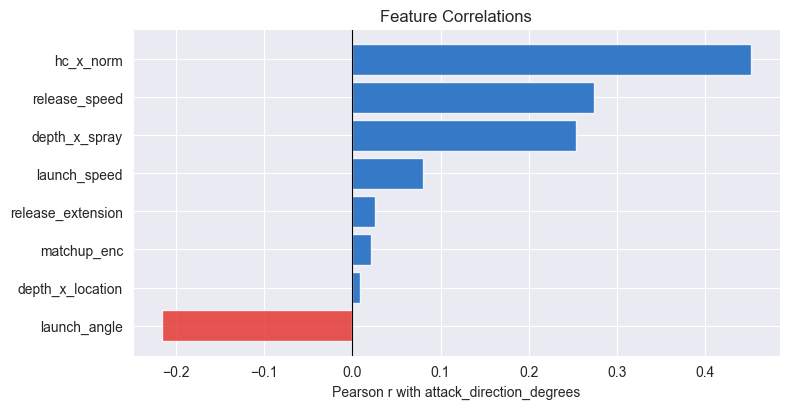

In [487]:
# ── Correlations with attack_direction_degrees ────────────────────────────────
corr = df_model[ALL_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(corr) + 1))
colors = ["#E53935" if v < 0 else "#1565C0" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors, alpha=0.85)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Pearson r with attack_direction_degrees")
ax.set_title("Feature Correlations")
plt.tight_layout()
plt.show()


## 5. Train XGBoost
Edit the hyperparameters below. Key ones to tune:
- `min_child_weight` — higher = more regularisation against per-swing noise (recommend 15–30)
- `n_estimators` + `learning_rate` — more trees / lower LR = better fit, slower
- `max_depth` — 4–6 is typical for tabular sports data


In [488]:
# ── Train / validation split ──────────────────────────────────────────────────
X_raw = df_model[ALL_FEATURES].copy()
y     = df_model[TARGET].values

scaler = StandardScaler()
X_raw[NUMERIC_FEATURES] = scaler.fit_transform(X_raw[NUMERIC_FEATURES])
X = X_raw.values

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.15, random_state=42)
print(f"Train: {len(X_train):,}   Val: {len(X_val):,}")


Train: 96,330   Val: 17,000


In [489]:
# ── Hyperparameters (edit here) ───────────────────────────────────────────────
model = XGBRegressor(
    n_estimators        = 800,
    learning_rate       = 0.04,
    max_depth           = 7,
    subsample           = 0.8,
    colsample_bytree    = 0.8,
    min_child_weight    = 10,   # regularise against single-swing noise
    reg_lambda          = 2.0,
    random_state        = 42,
    eval_metric         = "mae",
    early_stopping_rounds = 40,
    verbosity           = 0,
    device              = "cpu",
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

preds_val = model.predict(X_val)
mae = mean_absolute_error(y_val, preds_val)
r2  = r2_score(y_val, preds_val)

print(f"Validation MAE  : {mae:.2f}°")
print(f"Validation R²   : {r2:.4f}")
print(f"Best iteration  : {model.best_iteration}")


Validation MAE  : 5.27°
Validation R²   : 0.5364
Best iteration  : 263


## 6. Evaluate

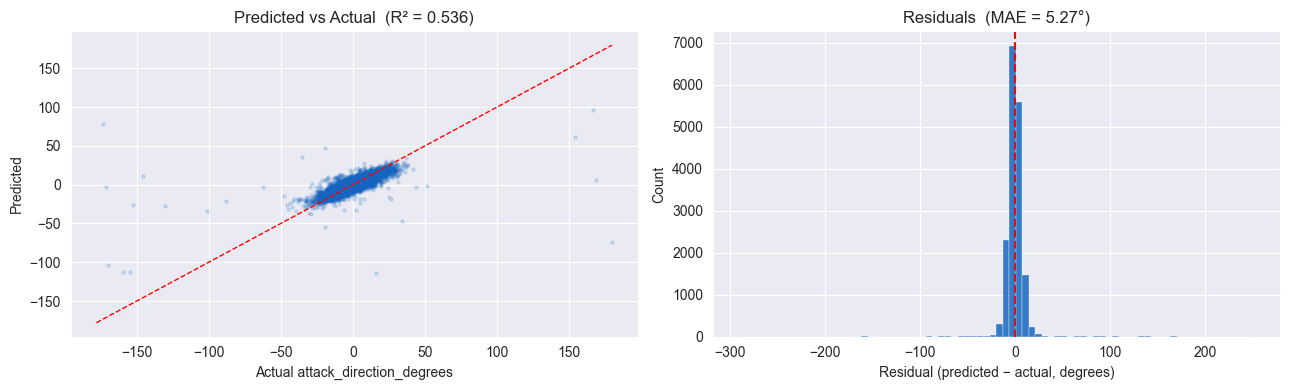

Residual std : 9.87°
Bias (mean)  : 0.042°


In [490]:
# ── Predicted vs. actual ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Scatter: predicted vs actual
sample_idx = np.random.choice(len(y_val), size=min(5000, len(y_val)), replace=False)
axes[0].scatter(y_val[sample_idx], preds_val[sample_idx],
                alpha=0.15, s=5, color="#1565C0")
lims = [min(y_val.min(), preds_val.min()), max(y_val.max(), preds_val.max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("Actual attack_direction_degrees")
axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Predicted vs Actual  (R² = {r2:.3f})")

# Residuals
residuals = preds_val - y_val
axes[1].hist(residuals, bins=80, color="#1565C0", alpha=0.85, edgecolor="white", linewidth=0.3)
axes[1].axvline(0, color="red", linewidth=1.5, linestyle="--")
axes[1].set_xlabel("Residual (predicted − actual, degrees)")
axes[1].set_ylabel("Count")
axes[1].set_title(f"Residuals  (MAE = {mae:.2f}°)")

plt.tight_layout()
plt.show()

print(f"Residual std : {residuals.std():.2f}°")
print(f"Bias (mean)  : {residuals.mean():.3f}°")


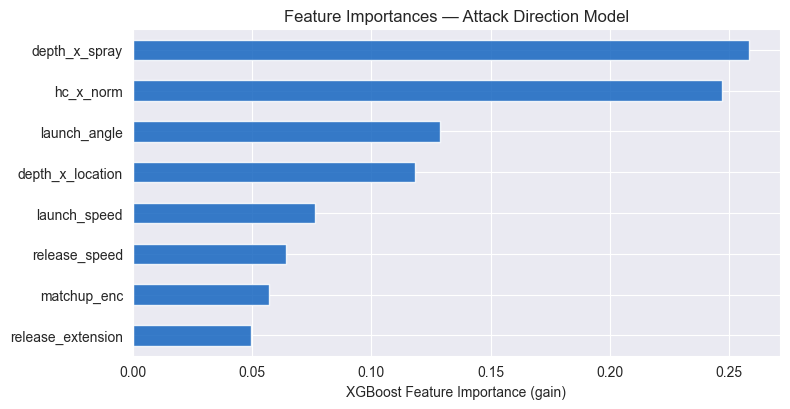

In [491]:
# ── Feature importance ────────────────────────────────────────────────────────
importances = pd.Series(model.feature_importances_, index=ALL_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(importances) + 1))
importances.plot.barh(ax=ax, color="#1565C0", alpha=0.85)
ax.set_xlabel("XGBoost Feature Importance (gain)")
ax.set_title("Feature Importances — Attack Direction Model")
plt.tight_layout()
plt.show()


Qualified batters (≥25 swings): 539
r²     : 0.6505
slope  : 0.6505  (1.0 = perfect)
p-value: 1.11e-124


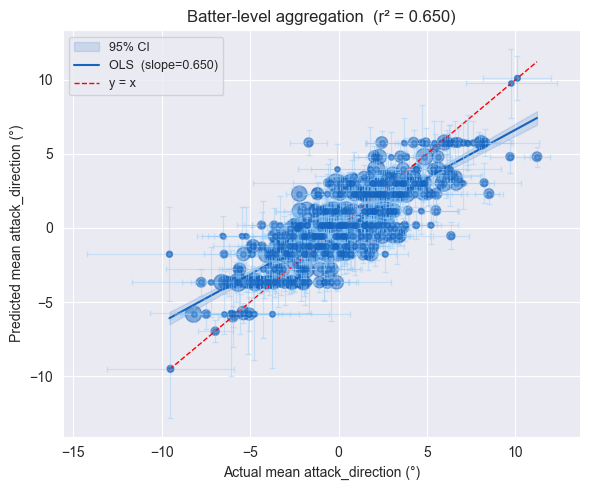

In [492]:
from scipy import stats

# ── Per-batter aggregation check ──────────────────────────────────────────────
df_model_pred = df_model.copy()
df_model_pred["pred"] = model.predict(X_raw.values)

df_model_pred["batter"] = df_swings.loc[df_model.index, "batter"].values

batter_agg = (
    df_model_pred
    .groupby("batter")
    .agg(
        n           = ("pred", "count"),
        mean_pred   = ("pred", "mean"),
        mean_actual = (TARGET, "mean"),
        se_pred     = ("pred", lambda x: x.std() / np.sqrt(len(x))),
        se_actual   = (TARGET, lambda x: x.std() / np.sqrt(len(x))),
    )
    .query("n >= 25")
    .sort_values("mean_actual")
    .reset_index()
)

from sklearn.isotonic import IsotonicRegression
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(batter_agg["mean_pred"], batter_agg["mean_actual"])
batter_agg["mean_pred_cal"] = iso.predict(batter_agg["mean_pred"])

# ── OLS: mean_pred ~ mean_actual ──────────────────────────────────────────────
x = batter_agg["mean_actual"].values
y = batter_agg["mean_pred_cal"].values
n = len(x)

slope, intercept, r, p_val, se_slope = stats.linregress(x, y)
r2 = r**2

y_hat    = intercept + slope * x
residuals = y - y_hat
mse      = (residuals**2).sum() / (n - 2)

# 95% CI band around the regression line
x_range  = np.linspace(x.min(), x.max(), 200)
y_range  = intercept + slope * x_range
x_mean   = x.mean()
se_band  = np.sqrt(mse * (1/n + (x_range - x_mean)**2 / ((x - x_mean)**2).sum()))
t_crit   = stats.t.ppf(0.975, df=n - 2)
ci_upper = y_range + t_crit * se_band
ci_lower = y_range - t_crit * se_band

print(f"Qualified batters (≥25 swings): {n}")
print(f"r²     : {r2:.4f}")
print(f"slope  : {slope:.4f}  (1.0 = perfect)")
print(f"p-value: {p_val:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))

# CI band
ax.fill_between(x_range, ci_lower, ci_upper, alpha=0.15, color="#1565C0", label="95% CI")

# Regression line
ax.plot(x_range, y_range, color="#1565C0", linewidth=1.5, label=f"OLS  (slope={slope:.3f})")

# Identity line
ax.plot([x.min(), x.max()], [x.min(), x.max()], "r--", linewidth=1, label="y = x")

# Points with SE error bars
ax.errorbar(
    x, y,
    xerr=batter_agg["se_actual"],
    yerr=batter_agg["se_pred"],
    fmt="o", markersize=4, alpha=0.4,
    color="#1565C0", ecolor="#90CAF9",
    elinewidth=0.8, capsize=2,
)
ax.scatter(x, y, s=batter_agg["n"] / 3, alpha=0.5, color="#1565C0")
ax.set_xlabel("Actual mean attack_direction (°)")
ax.set_ylabel("Predicted mean attack_direction (°)")
ax.set_title(f"Batter-level aggregation  (r² = {r2:.3f})")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [493]:
from scipy.stats import spearmanr
rho, p = spearmanr(batter_agg["mean_actual"], batter_agg["mean_pred"])
print(f"Spearman ρ  : {rho:.4f}")
print(f"p-value     : {p:.2e}")

Spearman ρ  : 0.7710
p-value     : 2.70e-107


In [494]:
meta = {
    "all_features":        ALL_FEATURES,
    "numeric_features":    NUMERIC_FEATURES,
    "pitch_type_map":      PITCH_TYPE_MAP,
    "stand_map":           STAND_MAP,
    "p_throws_map":        P_THROWS_MAP,
    "target":              TARGET,
    "val_mae":             float(mae),
    "val_r2":              float(r2),
    "n_train":             len(X_train),
    "n_val":               len(X_val),
    "mlb_mean":            float(y.mean()),
    "mlb_std":             float(y.std()),
    "feature_importances": dict(
        sorted(zip(ALL_FEATURES, model.feature_importances_),
               key=lambda x: x[1], reverse=True)
    ),
    # Within-side standardization constants — must match what engineer_features applied
    "hc_x_norm_mu":   {side: float(df[df["stand"]==side]["hc_x_norm"].mean())    for side in ["R","L"]},
    "hc_x_norm_sig":  {side: float(df[df["stand"]==side]["hc_x_norm"].std())     for side in ["R","L"]},
    "plate_x_rel_mu": {side: float(df[df["stand"]==side]["plate_x_rel"].mean())  for side in ["R","L"]},
    "plate_x_rel_sig":{side: float(df[df["stand"]==side]["plate_x_rel"].std())   for side in ["R","L"]},
}

In [495]:
from scipy.stats import spearmanr

# ── Reliability & stickiness analysis ────────────────────────────────────────
MIN_BBE  = 10
MAX_BBE  = 150
STEP     = 5
N_SPLITS = 200
N_ITEMS  = 5

df_rel = df_model_pred.copy()
thresholds = range(MIN_BBE, MAX_BBE + STEP, STEP)
results = []

for thresh in thresholds:
    eligible = (
        df_rel.groupby("batter")
        .filter(lambda x: len(x) >= thresh * N_ITEMS)
        ["batter"].unique()
    )
    if len(eligible) < 20:
        continue

    sub = df_rel[df_rel["batter"].isin(eligible)]
    alphas = []

    for _ in range(N_SPLITS):
        items = (
            sub.groupby("batter")
            .apply(lambda x: x.sample(frac=1, random_state=None)
                              .assign(item=lambda d: np.arange(len(d)) % N_ITEMS))
            .reset_index(drop=True)
            .groupby(["batter", "item"])["pred"]
            .mean()
            .unstack("item")
            .dropna()
        )
        k         = items.shape[1]
        item_var  = items.var(axis=0, ddof=1).sum()
        total_var = items.sum(axis=1).var(ddof=1)
        alpha     = (k / (k - 1)) * (1 - item_var / total_var)
        alphas.append(alpha)

    results.append({
        "thresh":     thresh,
        "n_batters":  len(eligible),
        "alpha_mean": np.mean(alphas),
        "alpha_std":  np.std(alphas),
    })

rel = pd.DataFrame(results)

Loading 2025 from cache …
0.900   40.090
Name: intercept_ball_minus_batter_pos_y_inches, dtype: Float64
2024 model rows: 113,330
2025 model rows: 118,519

Paired batters (≥25 BBE each season): 297
Stickiness (2024→2025):  ρ = 0.7723,  p = 4.51e-60


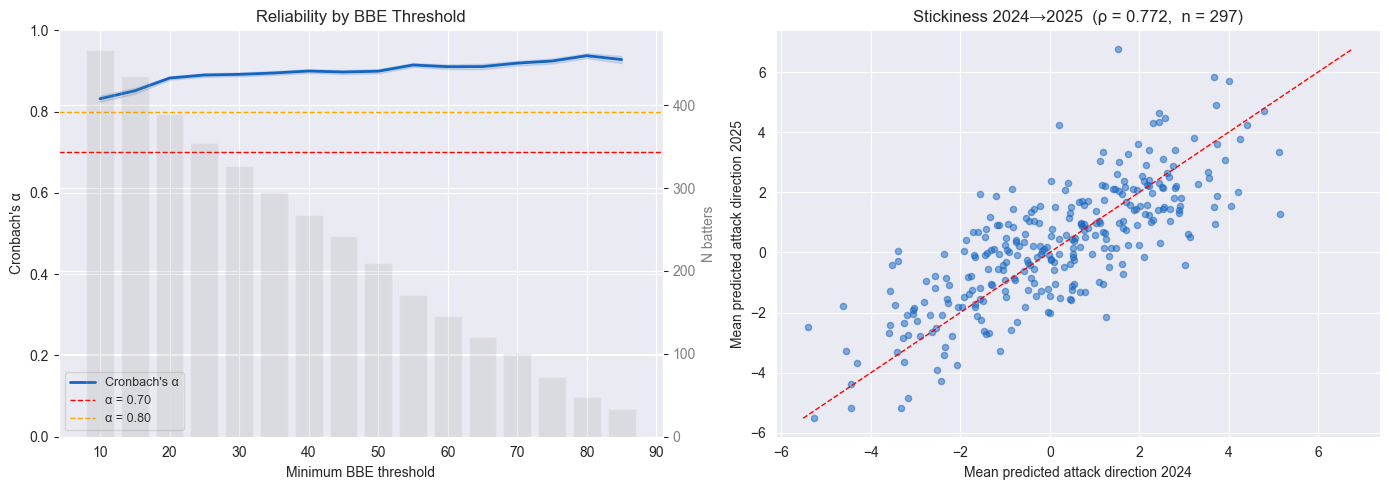

 thresh  n_batters  alpha_mean  alpha_std
     10        467       0.832      0.008
     15        435       0.851      0.007
     20        390       0.883      0.004
     25        354       0.890      0.005
     30        327       0.892      0.005
     35        295       0.895      0.005
     40        267       0.900      0.005
     45        242       0.898      0.005
     50        210       0.900      0.005
     55        171       0.915      0.005
     60        146       0.911      0.006
     65        120       0.911      0.007
     70        101       0.919      0.006
     75         72       0.925      0.006
     80         48       0.938      0.006
     85         34       0.928      0.009


In [523]:


# ── Stickiness: pull 2025 from Baseball Savant and pair with 2024 ─────────────
CACHE_2025 = Path("statcast_2025.parquet")

if CACHE_2025.exists():
    print("Loading 2025 from cache …")
    raw_2025 = pd.read_parquet(CACHE_2025)
else:
    print("Pulling 2025 from Baseball Savant …")
    chunks = []
    date_ranges_2025 = [
        ("2025-03-20", "2025-04-30"),
        ("2025-05-01", "2025-05-31"),
        ("2025-06-01", "2025-06-30"),
        ("2025-07-01", "2025-07-31"),
        ("2025-08-01", "2025-08-31"),
        ("2025-09-01", "2025-09-28"),
    ]
    for start, end in date_ranges_2025:
        print(f"  {start} → {end}")
        chunk = statcast(start, end, verbose=False)
        chunks.append(chunk)
    raw_2025 = pd.concat(chunks, ignore_index=True)
    raw_2025.to_parquet(CACHE_2025)
    print(f"Cached to {CACHE_2025}")

# Apply same contact filter and engineer features
swing_mask_2025 = (
    raw_2025[TARGET].notna() &
    raw_2025["bat_speed"].notna() &
    raw_2025["swing_length"].notna() &
    raw_2025["launch_speed"].notna() &
    raw_2025["hc_x"].notna() &
    raw_2025["stand"].notna() &
    raw_2025["pitch_type"].notna()
)
df_2025 = engineer_features(raw_2025[swing_mask_2025].copy())

# Re-apply within-side standardization using MLB 2024 constants from meta
# Apply within-side standardization using 2024 constants from meta
for side in ["R", "L"]:
    mask = df_2025["stand"] == side
    df_2025.loc[mask, "hc_x_norm_std"] = (
        (df_2025.loc[mask, "hc_x_norm"] - meta["hc_x_norm_mu"][side])
        / meta["hc_x_norm_sig"][side]
    )

# Recompute depth interactions using standardized hc_x_norm
df_2025["depth_x_spray"]    = df_2025["contact_depth_bin"] * df_2025["hc_x_norm_std"]
df_2025["depth_x_location"] = df_2025["contact_depth_bin"] * df_2025["plate_x_rel"]
df_model = df[ALL_FEATURES + [TARGET]].dropna()
print(f"2024 model rows: {len(df_model):,}")

df_2025_model = df_2025[ALL_FEATURES + [TARGET]].dropna()
print(f"2025 model rows: {len(df_2025_model):,}")
X_2025 = df_2025_model[ALL_FEATURES].copy()
X_2025[NUMERIC_FEATURES] = scaler.transform(X_2025[NUMERIC_FEATURES])

df_2025_model["pred"]   = model.predict(X_2025.values)
df_2025_model["batter"] = raw_2025.loc[df_2025_model.index, "batter"].values

# Aggregate both seasons
def batter_means(df, min_bbe=100):
    return (
        df.groupby("batter")["pred"]
        .agg(n="count", mean="mean")
        .query(f"n >= {min_bbe}")
    )

agg_2024 = batter_means(df_model_pred).rename(columns={"mean": "y2024", "n": "n_2024"})
agg_2025 = batter_means(df_2025_model).rename(columns={"mean": "y2025", "n": "n_2025"})

paired = agg_2024.join(agg_2025, how="inner")
print(f"\nPaired batters (≥25 BBE each season): {len(paired)}")

stickiness = None
if len(paired) >= 20:
    rho, p = spearmanr(paired["y2024"], paired["y2025"])
    stickiness = {"rho": rho, "p": p, "n": len(paired)}
    print(f"Stickiness (2024→2025):  ρ = {rho:.4f},  p = {p:.2e}")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
ax2 = ax1.twinx()

ax1.plot(rel["thresh"], rel["alpha_mean"], color="#1565C0", linewidth=2,
         label="Cronbach's α")
ax1.fill_between(rel["thresh"],
                 rel["alpha_mean"] - rel["alpha_std"],
                 rel["alpha_mean"] + rel["alpha_std"],
                 alpha=0.15, color="#1565C0")
ax1.axhline(0.70, color="red",    linewidth=1, linestyle="--", label="α = 0.70")
ax1.axhline(0.80, color="orange", linewidth=1, linestyle="--", label="α = 0.80")
ax1.set_xlabel("Minimum BBE threshold")
ax1.set_ylabel("Cronbach's α")
ax1.set_title("Reliability by BBE Threshold")
ax1.legend(fontsize=9)
ax1.set_ylim(0, 1)

ax2.bar(rel["thresh"], rel["n_batters"], alpha=0.15, color="gray", width=STEP * 0.8)
ax2.set_ylabel("N batters", color="gray")
ax2.tick_params(axis="y", labelcolor="gray")

if stickiness:
    axes[1].scatter(paired["y2024"], paired["y2025"], alpha=0.5, s=20, color="#1565C0")
    lims = [paired[["y2024","y2025"]].min().min(), paired[["y2024","y2025"]].max().max()]
    axes[1].plot(lims, lims, "r--", linewidth=1)
    axes[1].set_xlabel("Mean predicted attack direction 2024")
    axes[1].set_ylabel("Mean predicted attack direction 2025")
    axes[1].set_title(f"Stickiness 2024→2025  (ρ = {stickiness['rho']:.3f},  "
                      f"n = {stickiness['n']})")
else:
    axes[1].text(0.5, 0.5, "Not enough paired batters",
                 ha="center", va="center", transform=axes[1].transAxes, fontsize=11)
    axes[1].set_title("Stickiness 2024→2025")

plt.tight_layout()
plt.show()

print(rel[["thresh", "n_batters", "alpha_mean", "alpha_std"]].to_string(index=False))

In [505]:
# Raw BBE counts before feature filtering
raw_counts_24 = df_swings["batter"].value_counts()
raw_counts_25 = raw_2025.loc[raw_2025["launch_speed"].notna(), "batter"].value_counts()

paired_raw_n = raw_counts_24.rename("n_2024").to_frame().join(
    raw_counts_25.rename("n_2025"), how="inner"
)

for min_bbe in [25, 50, 75, 100]:
    sub = paired_raw_n.query(f"n_2024 >= {min_bbe} and n_2025 >= {min_bbe}")
    print(f"min_bbe={min_bbe:3d}  paired batters in raw data: {len(sub)}")

min_bbe= 25  paired batters in raw data: 458
min_bbe= 50  paired batters in raw data: 404
min_bbe= 75  paired batters in raw data: 368
min_bbe=100  paired batters in raw data: 334


In [508]:
# Check BBE counts before and after depth-related dropna for both seasons
raw_counts_24_all   = df_swings["batter"].value_counts()
raw_counts_25_all   = raw_2025.loc[raw_2025["launch_speed"].notna(), "batter"].value_counts()

depth_col = "intercept_ball_minus_batter_pos_y_inches"

df_swings_with_depth = df_swings[df_swings[depth_col].notna()]
raw_2025_with_depth  = raw_2025[raw_2025[depth_col].notna() & raw_2025["launch_speed"].notna()]

raw_counts_24_depth = df_swings_with_depth["batter"].value_counts()
raw_counts_25_depth = raw_2025_with_depth["batter"].value_counts()

print(f"{'min_bbe':>10}  {'2024 all':>10}  {'2024 depth':>10}  {'2024 lost':>10}  {'2025 all':>10}  {'2025 depth':>10}  {'2025 lost':>10}")
for min_bbe in [25, 50, 75, 100]:
    n_24_all   = (raw_counts_24_all   >= min_bbe).sum()
    n_24_depth = (raw_counts_24_depth >= min_bbe).sum()
    n_25_all   = (raw_counts_25_all   >= min_bbe).sum()
    n_25_depth = (raw_counts_25_depth >= min_bbe).sum()
    print(f"{min_bbe:>10}  {n_24_all:>10}  {n_24_depth:>10}  {n_24_all - n_24_depth:>10}  "
          f"{n_25_all:>10}  {n_25_depth:>10}  {n_25_all - n_25_depth:>10}")

   min_bbe    2024 all  2024 depth   2024 lost    2025 all  2025 depth   2025 lost
        25         539         539           0         606         592          14
        50         467         467           0         565         555          10
        75         435         435           0         521         510          11
       100         390         390           0         485         478           7


In [516]:
# Recompute contact_depth_bin for both seasons
for dataset in [df, df_2025]:
    depth_raw = dataset["intercept_ball_minus_batter_pos_y_inches"].fillna(
        df["intercept_ball_minus_batter_pos_y_inches"].median()
    )
    dataset["contact_depth_bin"] = pd.cut(
        depth_raw,
        bins=meta["contact_depth_bins"],
        labels=[0, 1],
        right=True,
    ).astype(float)

# Recompute within-side standardization for both seasons using 2024 constants
for dataset in [df, df_2025]:
    for side in ["R", "L"]:
        mask = dataset["stand"] == side
        dataset.loc[mask, "hc_x_norm_std"] = (
            (dataset.loc[mask, "hc_x_norm"] - meta["hc_x_norm_mu"][side])
            / meta["hc_x_norm_sig"][side]
        )

# Recompute interactions
for dataset in [df, df_2025]:
    dataset["depth_x_spray"]    = dataset["contact_depth_bin"] * dataset["hc_x_norm_std"]
    dataset["depth_x_location"] = dataset["contact_depth_bin"] * dataset["plate_x_rel"]

# Verify
for name, dataset in [("2024", df), ("2025", df_2025)]:
    print(f"\n{name} contact_depth_bin missingness: {dataset['contact_depth_bin'].isna().mean():.3f}")
    print(f"{name} depth_x_spray missingness:    {dataset['depth_x_spray'].isna().mean():.3f}")
    print(dataset["contact_depth_bin"].value_counts().sort_index())


2024 contact_depth_bin missingness: 0.000
2024 depth_x_spray missingness:    0.000
contact_depth_bin
0.000    102004
1.000     11333
Name: count, dtype: int64

2025 contact_depth_bin missingness: 0.000
2025 depth_x_spray missingness:    0.000
contact_depth_bin
0.000    106315
1.000     12209
Name: count, dtype: int64


In [506]:
print("2024 contact depth missingness:", df_swings["intercept_ball_minus_batter_pos_y_inches"].isna().mean().round(3))
print("2025 contact depth missingness:", raw_2025["intercept_ball_minus_batter_pos_y_inches"].isna().mean().round(3))

2024 contact depth missingness: 0.0
2025 contact depth missingness: 0.55


In [497]:
print("2024 mean pred:", df_model_pred["pred"].mean().round(3))
print("2025 mean pred:", df_2025_model["pred"].mean().round(3))

# Check if the shift is uniform or batter-specific
print("\nPaired difference stats:")
print((paired["y2025"] - paired["y2024"]).describe().round(3))

# Check if it's handedness-driven
for side in ["R", "L"]:
    mask_24 = df_model_pred["batter"].isin(
        paired.index) & (df_swings.loc[df_model_pred.index, "stand"] == side)
    mask_25 = df_2025_model["batter"].isin(
        paired.index) & (df_2025["stand"] == side)
    print(f"\n{side}HH  2024: {df_model_pred.loc[mask_24, 'pred'].mean():.3f}"
          f"  2025: {df_2025_model.loc[mask_25, 'pred'].mean():.3f}")

2024 mean pred: 0.229
2025 mean pred: 0.329

Paired difference stats:
count   284.000
mean      0.014
std       1.979
min      -6.234
25%      -1.127
50%      -0.038
75%       1.167
max       7.076
dtype: float64

RHH  2024: 0.077  2025: 0.005

LHH  2024: 0.531  2025: 0.621


In [498]:
cols_to_check = ["hc_x_norm", "launch_speed", "launch_angle",
                 "release_speed", "contact_depth_bin",
                 "intercept_ball_minus_batter_pos_y_inches"]

for col in cols_to_check:
    if col in df_model_pred.columns and col in df_2025_model.columns:
        m24 = df_model_pred[col].mean()
        m25 = df_2025_model[col].mean()
        print(f"{col:45s}  2024: {m24:7.3f}   2025: {m25:7.3f}   diff: {m25-m24:+.3f}")

hc_x_norm                                      2024:  -5.456   2025:  -5.203   diff: +0.252
launch_speed                                   2024:  88.187   2025:  88.672   diff: +0.485
launch_angle                                   2024:  13.476   2025:  13.499   diff: +0.023
release_speed                                  2024:  89.259   2025:  89.517   diff: +0.258


In [500]:
print("intercept_ball_minus_batter_pos_y_inches:")
print("2024 mean:", df[df.index.isin(df_model.index)]["intercept_ball_minus_batter_pos_y_inches"].mean().round(3))
print("2025 mean:", df_2025["intercept_ball_minus_batter_pos_y_inches"].mean().round(3))

print("\ncontact_depth_bin:")
print("2024:\n", df[df.index.isin(df_model.index)]["contact_depth_bin"].value_counts(normalize=True).sort_index().round(3))
print("2025:\n", df_2025["contact_depth_bin"].value_counts(normalize=True).sort_index().round(3))

intercept_ball_minus_batter_pos_y_inches:
2024 mean: 29.973
2025 mean: 30.013

contact_depth_bin:
2024:
 contact_depth_bin
0.000   0.900
1.000   0.100
2.000   0.000
Name: proportion, dtype: float64
2025:
 contact_depth_bin
0.000   0.903
1.000   0.097
Name: proportion, dtype: float64


In [342]:
print(df["intercept_ball_minus_batter_pos_y_inches"].describe().round(2))

count   113330.000
mean        29.970
std          7.810
min         -2.190
25%         24.700
50%         29.860
75%         35.150
max         66.540
Name: intercept_ball_minus_batter_pos_y_inches, dtype: Float64


## 7. Save Artifacts
Saves the trained model, scaler, and metadata to `models/`.  
The apply script loads these exact files.


In [ ]:
# ── Save ─────────────────────────────────────────────────────────────────────
model.save_model(str(MODEL_DIR / "attack_direction_model.json"))
joblib.dump(scaler, MODEL_DIR / "attack_direction_scaler.pkl")

meta = {
    "all_features":      ALL_FEATURES,
    "numeric_features":  NUMERIC_FEATURES,
    "pitch_type_map":    PITCH_TYPE_MAP,
    "stand_map":         STAND_MAP,
    "p_throws_map":      P_THROWS_MAP,
    "target":            TARGET,
    "val_mae":           float(mae),
    "val_r2":            float(r2),
    "n_train":           len(X_train),
    "n_val":             len(X_val),
    "mlb_mean":          float(y.mean()),
    "mlb_std":           float(y.std()),
    "feature_importances": dict(
        sorted(zip(ALL_FEATURES, model.feature_importances_),
               key=lambda x: x[1], reverse=True)
    ),
}
joblib.dump(meta, MODEL_DIR / "attack_direction_meta.pkl")

print("Saved:")
print(f"  models/attack_direction_model.json")
print(f"  models/attack_direction_scaler.pkl")
print(f"  models/attack_direction_meta.pkl")
print(f"\nMLB population stats (for FL normalisation later):")
print(f"  mean attack_direction : {meta['mlb_mean']:.2f}°")
print(f"  std  attack_direction : {meta['mlb_std']:.2f}°")
